In [17]:
 # Step 1 Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [18]:
# Step 2: Load the cleaned hotel booking dataset
df = pd.read_csv("Hotel_Booking_Cleaned.csv", encoding="utf-8-sig")

# Display the first 5 rows of the dataset
print(df.head())

  Booking_ID Booking_Date Check_In_Date Check_Out_Date Customer_ID  \
0     B10001    4/13/2025     5/31/2025       6/3/2025      C24750   
1     B10002    3/12/2026     3/25/2026      3/28/2026      C24413   
2     B10003    9/28/2025     9/28/2025      10/4/2025      C24651   
3     B10004    4/17/2025      7/6/2025      7/10/2025      C23779   
4     B10005    3/13/2025      4/6/2025       4/8/2025      C21402   

  Customer_Type       City Hotel_Type Room_Type Booking_Channel  ...  \
0       Leisure       Pune     Luxury     Suite    Travel Agent  ...   
1       Leisure       Pune     Budget   Premium         Website  ...   
2       Leisure  Bengaluru     Luxury    Deluxe     Booking App  ...   
3       Leisure      Delhi     Budget   Premium         Website  ...   
4       Leisure  Hyderabad     Luxury  Standard     Booking App  ...   

  Booking_Status  Cancellation  Rating  Stay_Duration  Lead_Days  \
0      Confirmed            No     4.3              3         48   
1      Con

In [19]:
# Step 3: Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Display the total number of rows
print("Total Rows:", df.shape[0])

# Display the total number of columns
print("Total Columns:", df.shape[1])

Dataset Shape: (10000, 26)
Total Rows: 10000
Total Columns: 26


In [22]:
# Step 4: Display all column names
print("Column Names:")

# Convert the column names into a list and display them
print(df.columns.tolist())

Column Names:
['Booking_ID', 'Booking_Date', 'Check_In_Date', 'Check_Out_Date', 'Customer_ID', 'Customer_Type', 'City', 'Hotel_Type', 'Room_Type', 'Booking_Channel', 'Payment_Mode', 'Guests', 'Nights', 'Room_Rate', 'Discount', 'Total_Amount', 'Booking_Status', 'Cancellation', 'Rating', 'Stay_Duration', 'Lead_Days', 'Revenue_Before_Discount', 'Discount_Amount', 'Revenue_After_Discount', 'Booking_Month', 'Booking_Year']


In [23]:
# Step 5: Check missing values in each column
print("Missing Values in Each Column:")

# Count missing values in every column
print(df.isnull().sum())

Missing Values in Each Column:
Booking_ID                  0
Booking_Date                0
Check_In_Date               0
Check_Out_Date              0
Customer_ID                 0
Customer_Type               0
City                       15
Hotel_Type                  0
Room_Type                   0
Booking_Channel             0
Payment_Mode               15
Guests                      0
Nights                      0
Room_Rate                   0
Discount                    0
Total_Amount                0
Booking_Status              0
Cancellation                0
Rating                     20
Stay_Duration               0
Lead_Days                   0
Revenue_Before_Discount     0
Discount_Amount             0
Revenue_After_Discount      0
Booking_Month               0
Booking_Year                0
dtype: int64


In [24]:
# Step 6: Check duplicate records

# Count completely duplicated rows
print("Total Duplicate Rows:", df.duplicated().sum())

# Count duplicated Booking IDs
print("Duplicate Booking IDs:", df["Booking_ID"].duplicated().sum())

Total Duplicate Rows: 0
Duplicate Booking IDs: 0


In [25]:
# Step 7: Remove completely duplicated rows

# Store the number of rows before removing duplicates
rows_before = len(df)

# Remove completely duplicated rows
df = df.drop_duplicates()

# Store the number of rows after removing duplicates
rows_after = len(df)

# Display the cleaning results
print("Rows Before Cleaning:", rows_before)
print("Rows After Cleaning:", rows_after)
print("Duplicate Rows Removed:", rows_before - rows_after)

Rows Before Cleaning: 10000
Rows After Cleaning: 10000
Duplicate Rows Removed: 0


In [26]:
# Step 8: Handle missing values

# Replace missing City values with "Unknown"
df["City"] = df["City"].fillna("Unknown")

# Replace missing Payment_Mode values with "Unknown"
df["Payment_Mode"] = df["Payment_Mode"].fillna("Unknown")

# Check missing values after handling them
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Booking_ID                  0
Booking_Date                0
Check_In_Date               0
Check_Out_Date              0
Customer_ID                 0
Customer_Type               0
City                        0
Hotel_Type                  0
Room_Type                   0
Booking_Channel             0
Payment_Mode                0
Guests                      0
Nights                      0
Room_Rate                   0
Discount                    0
Total_Amount                0
Booking_Status              0
Cancellation                0
Rating                     20
Stay_Duration               0
Lead_Days                   0
Revenue_Before_Discount     0
Discount_Amount             0
Revenue_After_Discount      0
Booking_Month               0
Booking_Year                0
dtype: int64


In [27]:
# Step 9: Convert date columns to datetime format

# List the date columns in the dataset
date_columns = ["Booking_Date", "Check_In_Date", "Check_Out_Date"]

# Convert each column to datetime format
for column in date_columns:
    df[column] = pd.to_datetime(df[column], errors="coerce")

# Display the data types of the date columns
print(df[date_columns].dtypes)

Booking_Date      datetime64[us]
Check_In_Date     datetime64[us]
Check_Out_Date    datetime64[us]
dtype: object


In [28]:
# Step 10: Calculate stay duration and lead days

# Calculate the number of nights between check-in and check-out
df["Stay_Duration"] = (
    df["Check_Out_Date"] - df["Check_In_Date"]
).dt.days

# Calculate how many days before check-in the booking was made
df["Lead_Days"] = (
    df["Check_In_Date"] - df["Booking_Date"]
).dt.days

# Display the calculated columns for the first 5 records
print(df[[
    "Booking_Date",
    "Check_In_Date",
    "Check_Out_Date",
    "Stay_Duration",
    "Lead_Days"
]].head())

  Booking_Date Check_In_Date Check_Out_Date  Stay_Duration  Lead_Days
0   2025-04-13    2025-05-31     2025-06-03              3         48
1   2026-03-12    2026-03-25     2026-03-28              3         13
2   2025-09-28    2025-09-28     2025-10-04              6          0
3   2025-04-17    2025-07-06     2025-07-10              4         80
4   2025-03-13    2025-04-06     2025-04-08              2         24


In [29]:
# Step 11: Check invalid dates and negative values

# Count missing or invalid dates
print("Missing Booking Dates:", df["Booking_Date"].isna().sum())
print("Missing Check-In Dates:", df["Check_In_Date"].isna().sum())
print("Missing Check-Out Dates:", df["Check_Out_Date"].isna().sum())

# Count records with negative stay duration
print(
    "Negative Stay Duration:",
    (df["Stay_Duration"] < 0).sum()
)

# Count records with negative lead days
print(
    "Negative Lead Days:",
    (df["Lead_Days"] < 0).sum()
)

# Display records where check-out is before check-in
print("\nRecords with Invalid Stay Dates:")
print(df[df["Check_Out_Date"] < df["Check_In_Date"]][
    ["Booking_ID", "Check_In_Date", "Check_Out_Date"]
].head())

Missing Booking Dates: 0
Missing Check-In Dates: 0
Missing Check-Out Dates: 0
Negative Stay Duration: 0
Negative Lead Days: 0

Records with Invalid Stay Dates:
Empty DataFrame
Columns: [Booking_ID, Check_In_Date, Check_Out_Date]
Index: []


In [30]:
# Step 12: Calculate revenue columns

# Calculate revenue before discount
df["Gross_Revenue"] = df["Room_Rate"] * df["Nights"]

# Calculate the discount amount
df["Discount_Amount"] = df["Gross_Revenue"] * df["Discount"]

# Calculate revenue after discount
df["Net_Revenue"] = df["Gross_Revenue"] - df["Discount_Amount"]

# Display the revenue calculations for the first 5 records
print(df[[
    "Room_Rate",
    "Nights",
    "Discount",
    "Gross_Revenue",
    "Discount_Amount",
    "Net_Revenue"
]].head())

   Room_Rate  Nights  Discount  Gross_Revenue  Discount_Amount  Net_Revenue
0       9270       3      0.05          27810           1390.5      26419.5
1       6190       3      0.10          18570           1857.0      16713.0
2       5650       6      0.05          33900           1695.0      32205.0
3       7490       4      0.05          29960           1498.0      28462.0
4       3240       2      0.00           6480              0.0       6480.0


In [31]:
# Step 13: Analyze total revenue and average revenue

# Calculate total revenue after discount
total_revenue = df["Net_Revenue"].sum()

# Calculate average revenue per booking record
average_revenue = df["Net_Revenue"].mean()

# Display the results
print("Total Revenue:", round(total_revenue, 2))
print("Average Revenue:", round(average_revenue, 2))

Total Revenue: 178558169.5
Average Revenue: 17855.82


In [32]:
# Step 14: Analyze revenue by city

city_analysis = (
    df.groupby("City")
      .agg(
          Total_Bookings=("Booking_ID", "count"),
          Total_Revenue=("Net_Revenue", "sum")
      )
      .reset_index()
      .sort_values("Total_Revenue", ascending=False)
)

# Display the results
print(city_analysis)

         City  Total_Bookings  Total_Revenue
4         Goa            1006     18590010.0
0   Ahmedabad            1039     18400012.5
5   Hyderabad            1009     18334217.5
3       Delhi            1030     18214907.5
9        Pune             978     17818487.0
1   Bengaluru             977     17788253.5
7     Kolkata             995     17751319.5
8      Mumbai            1000     17634321.5
6      Jaipur             972     17007640.0
2     Chennai             979     16784825.5
10    Unknown              15       234175.0


In [33]:
# Step 15: Analyze performance by hotel type

hotel_analysis = (
    df.groupby("Hotel_Type")
      .agg(
          Total_Bookings=("Booking_ID", "count"),
          Total_Revenue=("Net_Revenue", "sum"),
          Average_Revenue=("Net_Revenue", "mean")
      )
      .reset_index()
      .sort_values("Total_Revenue", ascending=False)
)

# Display the results
print(hotel_analysis)

  Hotel_Type  Total_Bookings  Total_Revenue  Average_Revenue
2     Luxury            2526     57133691.5     22618.246833
1   Business            2963     49688136.5     16769.536450
3     Resort            2039     41297727.0     20253.912212
0     Budget            2472     30438614.5     12313.355380


In [34]:
# Step 16: Analyze performance by booking channel

channel_analysis = (
    df.groupby("Booking_Channel")
      .agg(
          Total_Bookings=("Booking_ID", "count"),
          Total_Revenue=("Net_Revenue", "sum"),
          Average_Revenue=("Net_Revenue", "mean")
      )
      .reset_index()
      .sort_values("Total_Revenue", ascending=False)
)

# Display the results
print(channel_analysis)

  Booking_Channel  Total_Bookings  Total_Revenue  Average_Revenue
4         Website            3434     61161561.5     17810.588672
0     Booking App            3026     53963740.5     17833.357733
1       Corporate            1307     23519299.5     17994.873374
2    Travel Agent            1223     21748183.0     17782.651676
3         Walk-in            1010     18165385.0     17985.529703


In [35]:
# Step 17: Analyze performance by customer type

customer_analysis = (
    df.groupby("Customer_Type")
      .agg(
          Total_Bookings=("Booking_ID", "count"),
          Total_Revenue=("Net_Revenue", "sum"),
          Average_Revenue=("Net_Revenue", "mean")
      )
      .reset_index()
      .sort_values("Total_Revenue", ascending=False)
)

# Display the results
print(customer_analysis)

  Customer_Type  Total_Bookings  Total_Revenue  Average_Revenue
0      Business            3088     54662089.0     17701.453692
3       Leisure            2929     52844796.5     18041.924377
2        Family            2199     40277452.5     18316.258527
1        Couple            1784     30773831.5     17249.905549


In [36]:
# Step 18: Analyze revenue by month

# Extract the month and year from the booking date
df["Booking_Month"] = df["Booking_Date"].dt.to_period("M")

# Calculate monthly bookings and revenue
monthly_analysis = (
    df.groupby("Booking_Month")
      .agg(
          Total_Bookings=("Booking_ID", "count"),
          Total_Revenue=("Net_Revenue", "sum")
      )
      .reset_index()
      .sort_values("Booking_Month")
)

# Display the results
print(monthly_analysis)

   Booking_Month  Total_Bookings  Total_Revenue
0        2025-01             421      7006390.0
1        2025-02             356      6084889.5
2        2025-03             425      7803235.5
3        2025-04             441      7699068.5
4        2025-05             432      7778549.0
5        2025-06             406      7349469.5
6        2025-07             437      8404912.5
7        2025-08             442      7614535.0
8        2025-09             386      7225900.5
9        2025-10             420      7536157.0
10       2025-11             399      6864690.5
11       2025-12             405      7940163.5
12       2026-01             446      7718195.0
13       2026-02             364      6321771.0
14       2026-03             439      7929368.5
15       2026-04             376      6585463.0
16       2026-05             422      7470210.5
17       2026-06             421      7470378.5
18       2026-07             452      8308110.0
19       2026-08             403      72

In [37]:
# Step 19: Analyze booking cancellations

cancellation_analysis = (
    df.groupby("Cancellation")
      .agg(
          Total_Bookings=("Booking_ID", "count"),
          Total_Revenue=("Net_Revenue", "sum")
      )
      .reset_index()
)

# Calculate the cancellation percentage
total_bookings = cancellation_analysis["Total_Bookings"].sum()

cancellation_analysis["Booking_Percentage"] = (
    cancellation_analysis["Total_Bookings"] / total_bookings * 100
)

# Display the results
print(cancellation_analysis.round(2))

  Cancellation  Total_Bookings  Total_Revenue  Booking_Percentage
0           No            8619    152611481.5               86.19
1          Yes            1381     25946688.0               13.81


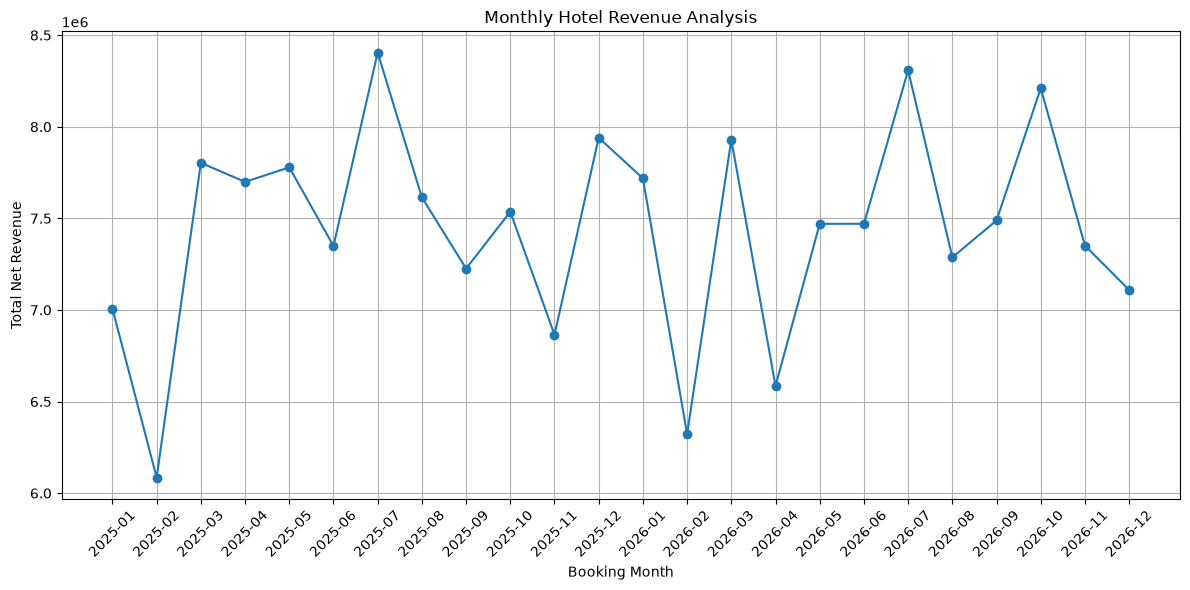

In [39]:
# Step 20: Visualize monthly revenue using a line chart

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_analysis["Booking_Month"].astype(str),
    monthly_analysis["Total_Revenue"],
    marker="o"
)

# Add chart title and labels
plt.title("Monthly Hotel Revenue Analysis")
plt.xlabel("Booking Month")
plt.ylabel("Total Net Revenue")

# Rotate month labels for better readability
plt.xticks(rotation=45)

# Display grid and adjust layout
plt.grid(True)
plt.tight_layout()
plt.show()

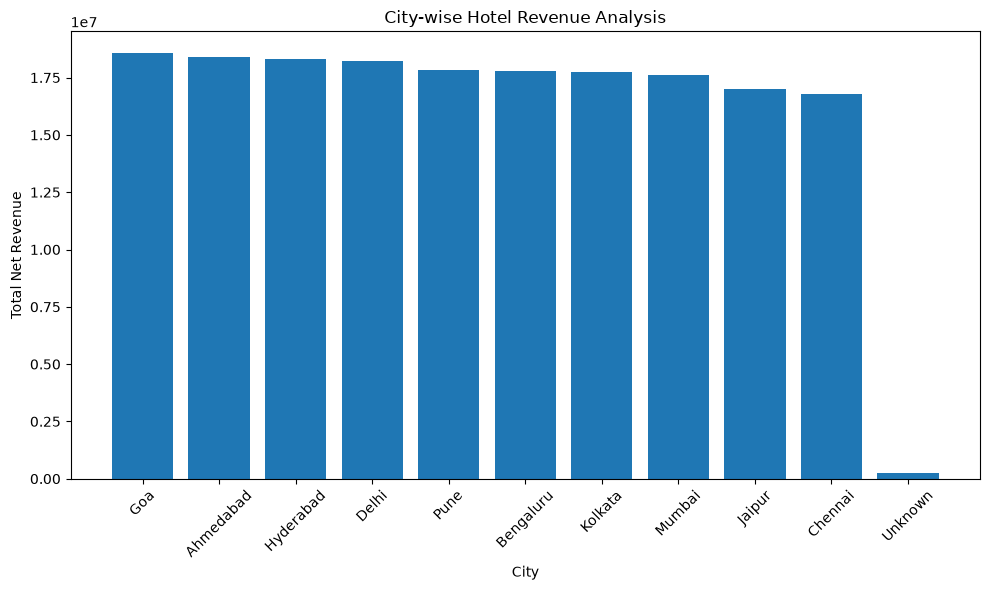

In [40]:
# Step 21: Visualize revenue by city

plt.figure(figsize=(10, 6))

plt.bar(
    city_analysis["City"],
    city_analysis["Total_Revenue"]
)

# Add chart title and axis labels
plt.title("City-wise Hotel Revenue Analysis")
plt.xlabel("City")
plt.ylabel("Total Net Revenue")

# Rotate city labels for readability
plt.xticks(rotation=45)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

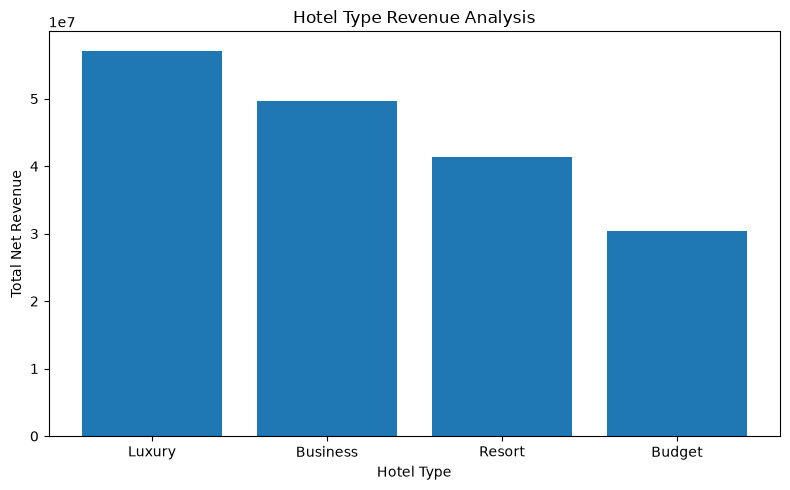

In [41]:
# Step 22: Visualize revenue by hotel type

plt.figure(figsize=(8, 5))

plt.bar(
    hotel_analysis["Hotel_Type"],
    hotel_analysis["Total_Revenue"]
)

# Add chart title and axis labels
plt.title("Hotel Type Revenue Analysis")
plt.xlabel("Hotel Type")
plt.ylabel("Total Net Revenue")

# Display the chart
plt.tight_layout()
plt.show()

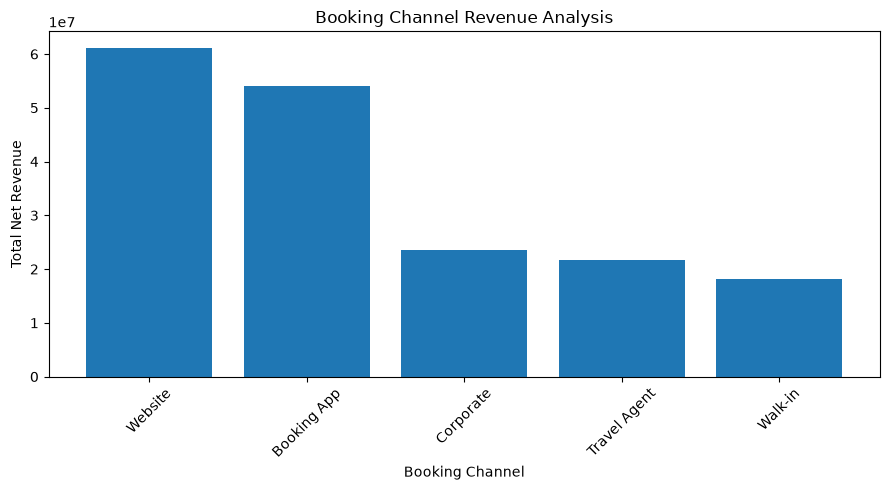

In [42]:
# Step 23: Visualize revenue by booking channel

plt.figure(figsize=(9, 5))

plt.bar(
    channel_analysis["Booking_Channel"],
    channel_analysis["Total_Revenue"]
)

# Add chart title and axis labels
plt.title("Booking Channel Revenue Analysis")
plt.xlabel("Booking Channel")
plt.ylabel("Total Net Revenue")

# Rotate labels for readability
plt.xticks(rotation=45)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

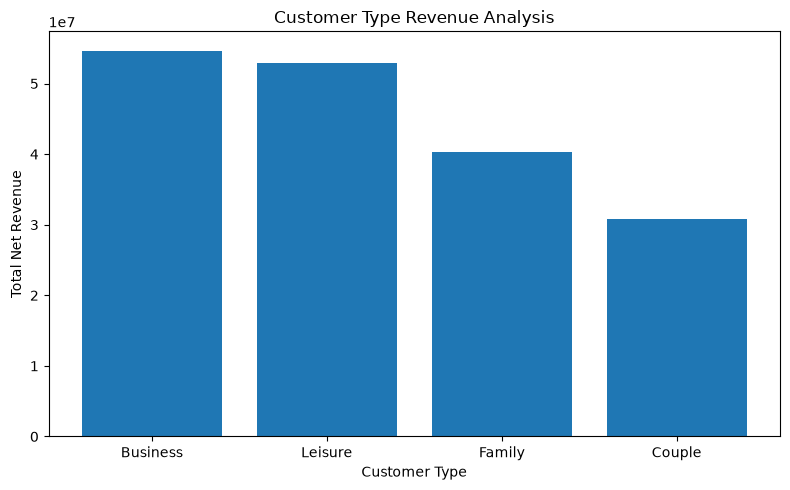

In [43]:
# Step 24: Visualize revenue by customer type

plt.figure(figsize=(8, 5))

plt.bar(
    customer_analysis["Customer_Type"],
    customer_analysis["Total_Revenue"]
)

# Add chart title and axis labels
plt.title("Customer Type Revenue Analysis")
plt.xlabel("Customer Type")
plt.ylabel("Total Net Revenue")

# Display the chart
plt.tight_layout()
plt.show()

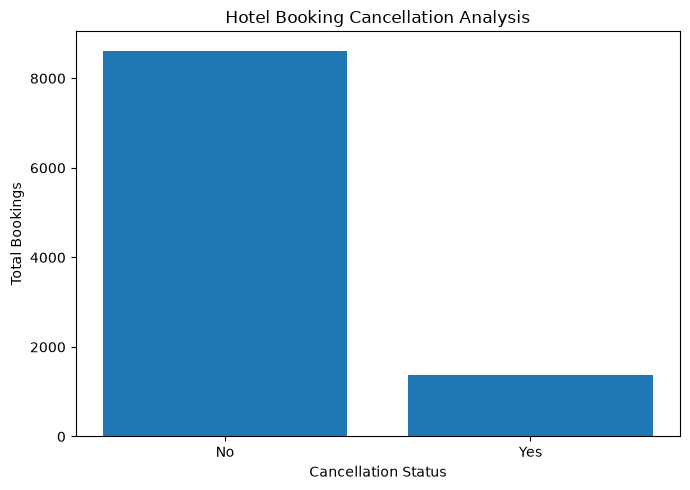

In [44]:
# Step 25: Visualize booking cancellations

plt.figure(figsize=(7, 5))

plt.bar(
    cancellation_analysis["Cancellation"].astype(str),
    cancellation_analysis["Total_Bookings"]
)

# Add chart title and axis labels
plt.title("Hotel Booking Cancellation Analysis")
plt.xlabel("Cancellation Status")
plt.ylabel("Total Bookings")

# Display the chart
plt.tight_layout()
plt.show()

In [45]:
# Step 26: Save the cleaned dataset

# Export the DataFrame to a CSV file without the index
df.to_csv("Hotel_Booking_Final.csv", index=False, encoding="utf-8-sig")

# Confirm that the file was saved
print("Final dataset saved successfully!")
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Final dataset saved successfully!
Total Rows: 10000
Total Columns: 28


In [46]:
# Step 27: Generate final business insights

# Identify the city with the highest revenue
top_city = city_analysis.loc[
    city_analysis["Total_Revenue"].idxmax()
]

# Identify the hotel type with the highest revenue
top_hotel = hotel_analysis.loc[
    hotel_analysis["Total_Revenue"].idxmax()
]

# Identify the booking channel with the highest revenue
top_channel = channel_analysis.loc[
    channel_analysis["Total_Revenue"].idxmax()
]

# Identify the customer type with the highest revenue
top_customer = customer_analysis.loc[
    customer_analysis["Total_Revenue"].idxmax()
]

# Display the business insights
print("HOTEL BOOKING BUSINESS INSIGHTS")
print("--------------------------------")
print("Total Net Revenue:", round(df["Net_Revenue"].sum(), 2))
print("Total Bookings:", df["Booking_ID"].nunique())

print("Top City:", top_city["City"])
print("Top Hotel Type:", top_hotel["Hotel_Type"])
print("Top Booking Channel:", top_channel["Booking_Channel"])
print("Top Customer Type:", top_customer["Customer_Type"])

HOTEL BOOKING BUSINESS INSIGHTS
--------------------------------
Total Net Revenue: 178558169.5
Total Bookings: 10000
Top City: Goa
Top Hotel Type: Luxury
Top Booking Channel: Website
Top Customer Type: Business
